# CPGs on the gecko

Last full run: 2026-10-22, 19 min 52 s, AMD Ryzen 7 5800.

Which of ARIEL's seven CPGs makes the prebuilt gecko walk furthest? Every CPG
gets the same body, world, time and search budget:

* Body: `gecko()`, 8 hinge joints, one oscillator per joint, all oscillators
  coupled to each other.
* World: `SimpleFlatWorld`, 10 s of simulated time per trial.
* Control: `Controller` calls the CPG every 4 physics steps (15 ms at the
  3.75 ms timestep) with the simulation time; the CPG integrates over that
  time.
* Score: the distance in the floor plane between the core's start and end
  positions, in metres.
* Search: CMA-ES from nevergrad over the CPG's parameters, each scaled to the
  range the CPG samples its initial values from. 150 trials per run, three
  runs (seeds 0, 1, 2) per CPG.

Three CPGs also get sensory feedback before each call:

* `AdaptiveHopfCPG`: the measured joint angle minus the commanded one, so its
  frequencies can drift towards what the body actually does.
* `TegotaeCPG` and `LearnableTegotaeCPG`: the load on each joint's limb, the
  vertical force of the floor on every body that joint moves, in newtons. The
  next section measures them on the resting gecko and checks that the floor
  carries its whole weight. For `LearnableTegotaeCPG` the search also tunes
  the 51 weights of its three networks, as the paper does with PGPE.

Each CPG's best parameters are saved as JSON, and its best gait is filmed,
in `__data__/cpg_locomotion/` under the folder the notebook runs in
(git-ignored; the notebook shows one frame of each). `tools/run_notebooks.py`
runs every notebook in a temporary folder and deletes it afterwards, so to
keep the files run this one in place from `tests/functional`:
`cd tests/functional/simulation && uv run --no-sync jupyter execute --inplace
cpg_locomotion.ipynb` (or open it in Jupyter there). Filming needs OpenGL: on a
machine without a working backend the notebook saves the parameters, skips
the videos and still runs every check.

The notebook is marked slow (about 22 minutes); `tools/run_notebooks.py`
runs it only with `--slow` or when named.

In [ ]:
# Run time: the last code cell prints how long the whole notebook took
import sys
import time

sys.stdout.write(f"Started {time.strftime('%Y-%m-%d %H:%M:%S %Z')}\n")
NOTEBOOK_STARTED = time.perf_counter()

In [1]:
from ariel.rendering import (  # chooses the OpenGL backend before MuJoCo loads
    VideoRecorder,
)

One-off setup: testing which OpenGL backends work on this machine. The result is saved to mujoco_user_config.json; 
this will not be repeated.

Output()

In [2]:
# Standard library
import os
import time

# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import nevergrad as ng
import numpy as np
from rich.console import Console

# Local libraries
from ariel import DATA
from ariel.body_phenotypes.robogen_lite.prebuilt_robots.gecko import gecko
from ariel.parameters import FrozenModel
from ariel.simulation import (
    AdaptiveHopfCPG,
    Controller,
    HopfCPG,
    LearnableTegotaeCPG,
    NaCPG,
    PhaseCPG,
    SimpleFlatWorld,
    SwingStanceCPG,
    TegotaeCPG,
    Tracker,
    create_fully_connected_adjacency,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 50  # keeps the notebook under 500 KB
console = Console()

MODELS = [
    HopfCPG,
    AdaptiveHopfCPG,
    PhaseCPG,
    SwingStanceCPG,
    NaCPG,
    TegotaeCPG,
    LearnableTegotaeCPG,
]
SECONDS = 10.0
STEPS_PER_CONTROL = 4
BUDGET = 150
SEEDS = [0, 1, 2]
# Set by ariel.rendering's probe only when a backend works (or by the user)
BACKEND = os.environ.get("MUJOCO_GL")

## The trial

One world is compiled once and reset before every trial.

In [3]:
world = SimpleFlatWorld()
world.spawn(gecko().spec, position=(0, 0, 0.1))
model = world.compile()
data = mujoco.MjData(model)
core = next(
    i for i in range(model.nbody) if model.body(i).name.endswith("core")
)
# qpos address of the joint each actuator drives
joint_qpos = model.jnt_qposadr[model.actuator_trnid[:, 0]]
adjacency = create_fully_connected_adjacency(model.nu)

# limb[a, b] is 1 when actuator a's joint moves body b
robot = model.body_rootid == model.body_rootid[core]
joint_body = model.jnt_bodyid[model.actuator_trnid[:, 0]]
limb = np.zeros((model.nu, model.nbody))
for body in range(model.nbody):
    ancestor = body
    while ancestor != 0:
        limb[joint_body == ancestor, body] = 1.0
        ancestor = model.body_parentid[ancestor]
contact_force = np.zeros(6)


def floor_forces(d):
    """Return the vertical floor force on each body of the robot.

    Returns
    -------
    np.ndarray
        One force per body, in newtons.
    """
    per_body = np.zeros(model.nbody)
    for index in range(d.ncon):
        contact = d.contact[index]
        first = model.geom_bodyid[contact.geom1]
        second = model.geom_bodyid[contact.geom2]
        if robot[first] == robot[second]:
            continue  # the robot touching itself, or two pieces of the world
        mujoco.mj_contactForce(model, d, index, contact_force)
        on = first if robot[first] else second
        per_body[on] += contact_force[0] * abs(contact.frame[2])
    return per_body


def limb_loads(d):
    """Sum the vertical floor force on the bodies each joint moves.

    Returns
    -------
    np.ndarray
        One load per actuator, in newtons.
    """
    return limb @ floor_forces(d)


SETTLE = 2.0  # seconds for the gecko to come to rest, joints at 0
mujoco.mj_resetData(model, data)
while data.time < SETTLE:
    mujoco.mj_step(model, data)
weight = model.body_mass[robot].sum() * -model.opt.gravity[2]
on_floor = floor_forces(data).sum()
resting_loads = limb_loads(data)
console.print(
    f"weight {weight:.2f} N, floor force {on_floor:.2f} N, limb loads"
    f" {np.round(resting_loads, 2)} N"
)

console.print(
    f"{model.nu} actuators, timestep {model.opt.timestep * 1000:.1f} ms"
)


FRAME_RATE = 30  # frames per second asked for
STEPS_PER_FRAME = round(1 / (FRAME_RATE * model.opt.timestep))


def trial(cpg, film=None):
    """Run one 10 s trial; if film is given, pass it every rendered frame.

    Frames come from the same loop that scores the trial, every
    STEPS_PER_FRAME physics steps, seen by a camera that follows the core.

    Returns
    -------
    float
        The distance the core travelled in the floor plane, in metres.
    """
    mujoco.mj_resetData(model, data)
    mujoco.mj_forward(model, data)
    start = data.xpos[core, :2].copy()

    def callback(_model, d, *_args, **_kwargs):
        if isinstance(cpg, AdaptiveHopfCPG):
            cpg.set_input(d.qpos[joint_qpos] - d.ctrl)
        return cpg.forward(d.time).numpy()

    controller = Controller(
        controller_callback_function=callback,
        time_steps_per_ctrl_step=STEPS_PER_CONTROL,
        time_steps_per_save=10**9,
        tracker=Tracker(mujoco.mjtObj.mjOBJ_BODY, "core", ["xpos"]),
    )
    controller.tracker.setup(world.spec, data)
    renderer = None
    if film is not None:
        renderer = mujoco.Renderer(model, height=360, width=480)
        camera = mujoco.MjvCamera()
        camera.type = int(mujoco.mjtCamera.mjCAMERA_TRACKING)
        camera.trackbodyid = core
        camera.distance = 0.9
        camera.azimuth = 135
        camera.elevation = -30
    mujoco.set_mjcb_control(controller.set_control)
    step = 0
    try:
        while data.time < SECONDS:
            mujoco.mj_step(model, data)
            step += 1
            # Read the loads after the step: inside the control callback the
            # contacts are new but the contact forces are still the last
            # step's, so mj_contactForce would read stale values there.
            if isinstance(cpg, TegotaeCPG):  # LearnableTegotaeCPG too
                cpg.set_input(limb_loads(data))
            filming = film is not None and renderer is not None
            if filming and step % STEPS_PER_FRAME == 0:
                renderer.update_scene(data, camera=camera)
                film(renderer.render(), data.time)
    finally:
        mujoco.set_mjcb_control(None)
        if renderer is not None:
            renderer.close()
    return float(np.linalg.norm(data.xpos[core, :2] - start))

weight 24.82 N, floor force 24.82 N, limb loads [8.52 8.52 0.49 0.49 0.49 0.49 4.26 4.26] N

8 actuators, timestep 3.8 ms

In [ ]:
# Checks: the floor carries the resting gecko's whole weight, which the
# Tegotae CPGs' load inputs rely on, and no limb load is negative
WEIGHT_TOLERANCE = 0.02  # share of the weight
assert abs(on_floor - weight) < WEIGHT_TOLERANCE * weight
assert (resting_loads >= 0).all()

## The search

CMA-ES works in the unit cube; each point is scaled to the CPG's own
parameter bounds (for example `w` from 0 to 4 pi rad/s, amplitudes from 0 to
pi/2 rad) before it is set. Each search starts from the parameters the CPG
drew at random with that seed, not from the middle of the cube: the middle of
the Tegotae amplitude range (-pi/2 to pi/2) is a gecko that does not move.

In [4]:
def optimise(cpg_class, seed):
    """Search one CPG's parameters with CMA-ES.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        The score of every trial in order, and the best parameters.
    """
    cpg = cpg_class(adjacency, seed=seed)
    lower, upper = (b.numpy() for b in cpg.parameter_bounds())
    parametrization = ng.p.Array(
        shape=(cpg.num_of_parameters,), lower=0, upper=1
    )
    # start from the CPG's own seeded random parameters
    parametrization.value = (cpg.get_flat_params().numpy() - lower) / (
        upper - lower
    )
    parametrization.random_state = np.random.RandomState(seed)
    optimizer = ng.optimizers.CMA(
        parametrization=parametrization, budget=BUDGET
    )
    scores = []
    best, best_params = -1.0, None
    for _ in range(BUDGET):
        candidate = optimizer.ask()
        params = lower + candidate.value * (upper - lower)
        cpg.set_flat_params(params.astype(np.float32))
        score = trial(cpg)
        optimizer.tell(candidate, -score)
        scores.append(score)
        if score > best:
            best, best_params = score, params
    return np.array(scores), best_params


results = {}
seconds_per_trial = {}
for cpg_class in MODELS:
    started = time.perf_counter()
    runs = [optimise(cpg_class, seed) for seed in SEEDS]
    elapsed = time.perf_counter() - started
    seconds_per_trial[cpg_class.__name__] = elapsed / (BUDGET * len(SEEDS))
    results[cpg_class.__name__] = runs
    best = [scores.max() for scores, _ in runs]
    console.print(
        f"{cpg_class.__name__:16s} best per seed {np.round(best, 3)} m"
        f"  ({elapsed:.0f} s)"
    )

HopfCPG          best per seed [1.55  1.336 1.596] m  (135 s)

AdaptiveHopfCPG  best per seed [1.426 1.671 2.081] m  (160 s)

PhaseCPG         best per seed [1.054 1.73  2.44 ] m  (131 s)

SwingStanceCPG   best per seed [0.606 1.006 0.997] m  (142 s)

NaCPG            best per seed [1.106 1.293 1.511] m  (166 s)

TegotaeCPG       best per seed [0.463 0.741 0.585] m  (193 s)

LearnableTegotaeCPG best per seed [0.476 0.458 0.5  ] m  (238 s)

In [ ]:
# Checks: every CPG ran its searches to the full budget, and every
# trial gave a finite distance
assert set(results) == {cpg_class.__name__ for cpg_class in MODELS}
for name, runs in results.items():
    assert len(runs) == len(SEEDS), name
    for scores, params in runs:
        assert len(scores) == BUDGET, name
        assert np.isfinite(scores).all(), name
        assert params is not None, name

## Results

Best distance found so far against the number of trials, median of the three
seeds, with the range between the worst and the best seed shaded.

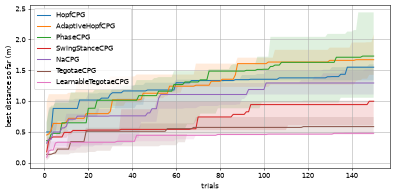

CPG              params median best  worst   best s/trial

HopfCPG              32       1.550  1.336  1.596    0.30

AdaptiveHopfCPG      32       1.671  1.426  2.081    0.36

PhaseCPG             32       1.730  1.054  2.440    0.29

SwingStanceCPG       40       0.997  0.606  1.006    0.32

NaCPG                40       1.293  1.106  1.511    0.37

TegotaeCPG           40       0.585  0.463  0.741    0.43

LearnableTegotaeCPG     83       0.476  0.458  0.500    0.53

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, runs in results.items():
    curves = np.array([np.maximum.accumulate(scores) for scores, _ in runs])
    trials = np.arange(1, BUDGET + 1)
    ax.plot(trials, np.median(curves, axis=0), label=name)
    ax.fill_between(trials, curves.min(axis=0), curves.max(axis=0), alpha=0.15)
ax.set_xlabel("trials")
ax.set_ylabel("best distance so far (m)")
ax.legend()
ax.grid(visible=True)
fig.tight_layout()
plt.show()

console.print(
    f"{'CPG':16s} {'params':>6s} {'median best':>11s} {'worst':>6s}"
    f" {'best':>6s} {'s/trial':>7s}"
)
table = {}
for name, runs in results.items():
    best = np.array([scores.max() for scores, _ in runs])
    table[name] = best
    n_params = len(runs[0][1])
    console.print(
        f"{name:16s} {n_params:6d} {np.median(best):11.3f} {best.min():6.3f}"
        f" {best.max():6.3f} {seconds_per_trial[name]:7.2f}"
    )

In [ ]:
# Checks: every CPG's best gait moves the gecko
WALKS = 0.1  # metres in 10 s
for name, best in table.items():
    assert np.isfinite(best).all(), name
    assert best.max() > WALKS, name

## The best gait of each CPG

The joint angles of each CPG's best parameters over the first 3 s, replayed
in the same world.

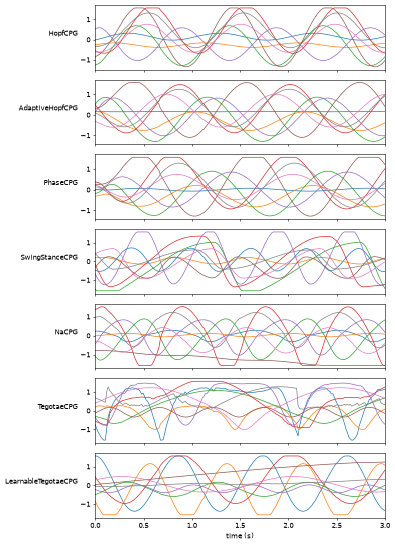

In [6]:
fig, axes = plt.subplots(len(MODELS), 1, figsize=(8, 11), sharex=True)
replayed = {}
for ax, cpg_class in zip(axes, MODELS, strict=True):
    runs = results[cpg_class.__name__]
    scores, params = max(runs, key=lambda run: run[0].max())
    cpg = cpg_class(adjacency, angle_tracking=True)
    cpg.set_flat_params(params.astype(np.float32))
    replayed[cpg_class.__name__] = (trial(cpg), scores.max())
    history = np.array(cpg.angle_history)
    times = np.arange(len(history)) * STEPS_PER_CONTROL * model.opt.timestep
    ax.plot(times, history, linewidth=1)
    ax.set_xlim(0, 3)
    ax.set_ylabel(cpg_class.__name__, rotation=0, ha="right")
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

In [ ]:
# Checks: replaying the best parameters gives the same distance (the
# trial is deterministic)
SAME = 1e-6  # metres
for name, (again, found) in replayed.items():
    assert abs(again - found) < SAME, name

## Parameters and videos of the best gaits

Each CPG's best parameters go to `best_<CPG>.json`, with the seed that found
them and the distance. With OpenGL, the best gait is then run once more with
the camera on, through the same `trial` that scored it, and written to
`best_<CPG>_<time stamp>.mp4`: one frame every `STEPS_PER_FRAME` physics steps
(9 at the 3.75 ms timestep, so 33.75 ms of simulation per frame, played at 30
frames per second: 1.3 % faster than real time). The frame at 5 s of each
video is shown below.

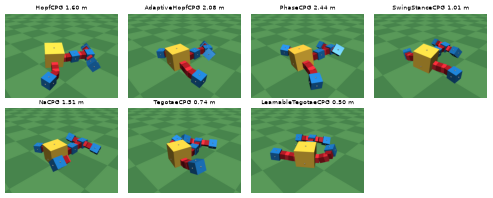

saved in /home/jmdm/projects/ariel-physical-checks/tests/functional/__data__/cpg_locomotion: 
best_AdaptiveHopfCPG.json, best_AdaptiveHopfCPG_20261022_041712.mp4, best_HopfCPG.json, 
best_HopfCPG_20261022_041710.mp4, best_LearnableTegotaeCPG.json, best_LearnableTegotaeCPG_20261022_041723.mp4, 
best_NaCPG.json, best_NaCPG_20261022_041718.mp4, best_PhaseCPG.json, best_PhaseCPG_20261022_041714.mp4, 
best_SwingStanceCPG.json, best_SwingStanceCPG_20261022_041716.mp4, best_TegotaeCPG.json, 
best_TegotaeCPG_20261022_041721.mp4

In [7]:
class BestGait(FrozenModel):
    """The best parameters one search found for one CPG."""

    cpg: str
    seed: int
    distance: float
    params: list[float]


OUTPUT = DATA / "cpg_locomotion"
OUTPUT.mkdir(parents=True, exist_ok=True)
best_gaits = {}
for cpg_class in MODELS:
    runs = results[cpg_class.__name__]
    index = max(range(len(runs)), key=lambda i: runs[i][0].max())
    gait = BestGait(
        cpg=cpg_class.__name__,
        seed=SEEDS[index],
        distance=float(runs[index][0].max()),
        params=[float(value) for value in runs[index][1]],
    )
    best_gaits[gait.cpg] = gait
    (OUTPUT / f"best_{gait.cpg}.json").write_text(
        gait.model_dump_json(indent=2)
    )

filmed = {}
stills = {}
if BACKEND is None:
    console.print("No working OpenGL backend: videos skipped.")
else:
    fps = round(1 / (STEPS_PER_FRAME * model.opt.timestep))
    for cpg_class in MODELS:
        gait = best_gaits[cpg_class.__name__]
        cpg = cpg_class(adjacency)
        cpg.set_flat_params(gait.params)
        recorder = VideoRecorder(
            file_name=f"best_{gait.cpg}",
            output_folder=OUTPUT,
            width=480,
            height=360,
            fps=fps,
        )

        def film(frame, now, recorder=recorder, name=gait.cpg):
            recorder.write(frame)
            if name not in stills and now >= SECONDS / 2:
                stills[name] = frame

        filmed[gait.cpg] = trial(cpg, film=film)
        recorder.release()
    fig, axes = plt.subplots(2, 4, figsize=(10, 4))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (name, frame) in zip(axes.flat, stills.items(), strict=False):
        ax.imshow(frame)
        ax.set_title(f"{name} {best_gaits[name].distance:.2f} m", fontsize=8)
    fig.tight_layout()
    plt.show()
console.print(
    f"saved in {OUTPUT}: "
    + ", ".join(sorted(path.name for path in OUTPUT.iterdir()))
)

In [ ]:
# Checks: every CPG's best gait is saved and reads back the same; with
# the camera on, the filmed run walks the same distance and its video is
# saved
for name, gait in best_gaits.items():
    saved = (OUTPUT / f"best_{name}.json").read_text()
    assert BestGait.model_validate_json(saved) == gait, name
for name, again in filmed.items():
    assert abs(again - best_gaits[name].distance) < SAME, name
    assert any(OUTPUT.glob(f"best_{name}_*")), name

# Run time of the whole notebook; after a full run, copy it into the
# "Last full run" line under the title
minutes, seconds = divmod(round(time.perf_counter() - NOTEBOOK_STARTED), 60)
console.print(f"Total run time: {minutes} min {seconds} s")